# Taller: construcción de un corpus lingüístico
**Clase espejo · Procesamiento del Lenguaje Natural**

En este cuaderno van a construir, paso a paso, un **mini corpus de reseñas de restaurantes de Bogotá**. Seguiremos las seis etapas vistas en clase:

1. Definir el objetivo
2. Diseñar la muestra
3. Recolectar (con metadatos y anonimización)
4. Limpiar y normalizar
5. Anotar (automática con spaCy y manual de sentimiento)
6. Medir la calidad y documentar (ficha técnica)

**Cómo usar este cuaderno**
- Ejecuten las celdas en orden con `Shift + Enter`.
- Las celdas marcadas con **EJERCICIO** son para que ustedes escriban o completen.
- Trabajen en parejas: en el paso 5 necesitarán dos anotadores.

## 0. Preparar el entorno
Instalamos spaCy, NLTK y el modelo pequeño de español `es_core_news_sm` (entrenado con noticias y textos web). Tarda un par de minutos la primera vez.

In [1]:
!pip install -q -U spacy nltk pandas
!python -m spacy download es_core_news_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')


In [2]:
import re, json, unicodedata
from collections import Counter
from datetime import date

import pandas as pd
import spacy

nlp = spacy.load("es_core_news_sm")
print("spaCy", spacy.__version__, "listo con el modelo", nlp.meta["name"])

spaCy 3.8.18 listo con el modelo core_news_sm


## 1. Definir el objetivo
Antes de reunir un solo texto decidimos **para qué** sirve el corpus. Escriban el objetivo en una o dos frases.

> Ejemplo: *Reunir reseñas reales de restaurantes de Bogotá para entrenar y evaluar un clasificador de sentimiento (positivo, negativo, neutro).*

In [3]:
# EJERCICIO: escriban el objetivo de su corpus
OBJETIVO = "Reunir reseñas en español de restaurantes de Bogotá para entrenar y evaluar un clasificador de sentimiento."
TAREAS_PREVISTAS = ["clasificación de sentimiento", "estudio del vocabulario gastronómico"]

## 2. Diseñar la muestra
El diseño fija **qué representa** el corpus. Completen las cinco decisiones:

| Decisión | Pregunta |
|---|---|
| Población | ¿Qué textos cuentan como parte del corpus? |
| Tamaño | ¿Cuántos textos o palabras se necesitan? |
| Balance | ¿En qué proporción entra cada categoría? |
| Periodo | ¿De qué fechas son los textos? |
| Metadatos | ¿Qué se registra de cada texto? |

In [4]:
# EJERCICIO: ajusten el diseño a su propio corpus
DISENO = {
    "poblacion": "Reseñas públicas en español de restaurantes de Bogotá",
    "tamano_objetivo": 30,                       # número de reseñas
    "balance": {"positivo": 1/3, "negativo": 1/3, "neutro": 1/3},
    "periodo": ("2023-01-01", "2025-12-31"),
    "metadatos": ["fecha", "fuente", "calificacion", "localidad"],
}
DISENO

{'poblacion': 'Reseñas públicas en español de restaurantes de Bogotá',
 'tamano_objetivo': 30,
 'balance': {'positivo': 0.3333333333333333,
  'negativo': 0.3333333333333333,
  'neutro': 0.3333333333333333},
 'periodo': ('2023-01-01', '2025-12-31'),
 'metadatos': ['fecha', 'fuente', 'calificacion', 'localidad']}

## 3. Recolectar
Cada texto entra con sus **metadatos** (para la trazabilidad). Aquí empezamos con reseñas de ejemplo escritas para la clase.

**Antes de usar un texto real**
- **Ley 1581 de 2012**: los datos personales requieren autorización y una finalidad clara.
- **Licencias**: revisen los términos de uso del sitio o dataset.
- **Anonimización**: retiren nombres, cédulas, teléfonos y correos.
- **Trazabilidad**: registren fuente, fecha y autor de cada texto.

In [5]:
reseñas = [
    {"texto": "El ajiaco estaba delicioso, volvería sin dudarlo.", "fecha": "2024-03-12", "fuente": "clase", "calificacion": 5, "localidad": "La Candelaria"},
    {"texto": "Pedí una bandeja paisa y llegó fría. Pésimo servicio.", "fecha": "2024-07-02", "fuente": "clase", "calificacion": 1, "localidad": "Kennedy"},
    {"texto": "Buen ambiente en Chapinero, aunque los precios son altos.", "fecha": "2023-11-20", "fuente": "clase", "calificacion": 3, "localidad": "Chapinero"},
    {"texto": "La mesera, Laura, fue muy amable. Escríbanme a laura.g@correo.com para reservar.", "fecha": "2025-01-15", "fuente": "clase", "calificacion": 5, "localidad": "Usaquén"},
    {"texto": "Esperamos 50 minutos   por una hamburguesa. Más info en https://ejemplo.com/resena", "fecha": "2024-09-08", "fuente": "clase", "calificacion": 2, "localidad": "Teusaquillo"},
    {"texto": "El lugar es normal, ni bueno ni malo. Llamen al 310 555 1234 si quieren domicilio.", "fecha": "2023-05-30", "fuente": "clase", "calificacion": 3, "localidad": "Suba"},
    {"texto": "¡Las arepas de choclo son las mejores de Bogotá!", "fecha": "2025-02-14", "fuente": "clase", "calificacion": 5, "localidad": "Engativá"},
    {"texto": "El café estaba aguado y el pan duro. No vuelvo.", "fecha": "2024-12-01", "fuente": "clase", "calificacion": 1, "localidad": "Chapinero"},
    {"texto": "Porciones pequeñas, pero la atención fue rápida.", "fecha": "2024-04-18", "fuente": "clase", "calificacion": 3, "localidad": "Fontibón"},
]
df = pd.DataFrame(reseñas)
df

,texto,fecha,fuente,calificacion,localidad
0,"El ajiaco estaba delicioso, volvería sin dudarlo.",2024-03-12,clase,5,La Candelaria
1,Pedí una bandeja paisa y llegó fría. Pésimo se...,2024-07-02,clase,1,Kennedy
2,"Buen ambiente en Chapinero, aunque los precios...",2023-11-20,clase,3,Chapinero
3,"La mesera, Laura, fue muy amable. Escríbanme a...",2025-01-15,clase,5,Usaquén
4,Esperamos 50 minutos por una hamburguesa. Má...,2024-09-08,clase,2,Teusaquillo
5,"El lugar es normal, ni bueno ni malo. Llamen a...",2023-05-30,clase,3,Suba
6,¡Las arepas de choclo son las mejores de Bogotá!,2025-02-14,clase,5,Engativá
7,El café estaba aguado y el pan duro. No vuelvo.,2024-12-01,clase,1,Chapinero
8,"Porciones pequeñas, pero la atención fue rápida.",2024-04-18,clase,3,Fontibón


### Opción: cargar reseñas desde un archivo CSV
Si ya tienen sus textos en una hoja de cálculo, guárdenla como CSV con las columnas `texto, fecha, fuente, calificacion, localidad` y súbanla con la celda siguiente.

In [6]:
# Descomenten estas líneas para subir su propio CSV
# from google.colab import files
# subido = files.upload()
# nombre = list(subido.keys())[0]
# df = pd.concat([df, pd.read_csv(nombre)], ignore_index=True)
# df.tail()

**EJERCICIO 3.1** Agreguen al menos **10 reseñas propias** (pueden ser inventadas o tomadas de sitios cuya licencia lo permita). Incluyan reseñas positivas, negativas y neutras para respetar el balance del diseño.

In [7]:
# EJERCICIO 3.1 (resuelto): 21 reseñas nuevas -> 30 en total, 10 por categoría
# Mezcla de reseñas claras, mixtas, irónicas y con datos personales (para practicar la anonimización).
nuevas = [
    # --- positivas (7)
    {"texto": "Los tamales tolimenses del domingo están buenísimos y el servicio fue muy amable.", "fecha": "2024-02-04", "fuente": "estudiante", "calificacion": 5, "localidad": "Bosa"},
    {"texto": "Mi comadre Marta me recomendó este sitio y no me defraudó: la trucha estuvo perfecta. Hablen con Marta al 301 456 7788.", "fecha": "2023-08-19", "fuente": "estudiante", "calificacion": 5, "localidad": "Ciudad Bolívar"},
    {"texto": "Precio justo, porciones generosas y un café de origen espectacular.", "fecha": "2025-03-22", "fuente": "estudiante", "calificacion": 4, "localidad": "Teusaquillo"},
    {"texto": "La comida estuvo deliciosa y el personal muy atento; puse dos estrellas por error.", "fecha": "2025-05-09", "fuente": "estudiante", "calificacion": 2, "localidad": "Chapinero"},
    {"texto": "Chévere el parche, la música suave y los postres de arequipe son una locura 😍", "fecha": "2024-10-27", "fuente": "estudiante", "calificacion": 5, "localidad": "Usaquén"},
    {"texto": "Excelente ceviche, fresco y bien presentado. Lo recomiendo a todos.", "fecha": "2023-09-14", "fuente": "estudiante", "calificacion": 5, "localidad": "Suba"},
    {"texto": "El domicilio llegó caliente y antes de lo prometido. Gracias, Andrés Pardo, por la atención.", "fecha": "2025-07-30", "fuente": "estudiante", "calificacion": 4, "localidad": "Kennedy"},
    # --- negativas (7)
    {"texto": "¡Qué maravilla esperar una hora por una sopa fría! Excelente servicio, sí señor.", "fecha": "2024-05-16", "fuente": "estudiante", "calificacion": 4, "localidad": "Chapinero"},
    {"texto": "El baño estaba sucio y el mesero nos ignoró toda la noche.", "fecha": "2023-03-03", "fuente": "estudiante", "calificacion": 1, "localidad": "Suba"},
    {"texto": "Carísimo para lo poco que sirven. No vuelvo ni regalado, parce.", "fecha": "2025-04-11", "fuente": "estudiante", "calificacion": 2, "localidad": "Usaquén"},
    {"texto": "Me cobraron dos veces la cuenta y nadie quiso corregirlo. Reclamos al 312-777-4455.", "fecha": "2024-08-23", "fuente": "estudiante", "calificacion": 1, "localidad": "Fontibón"},
    {"texto": "La carne llegó cruda y el administrador, Carlos Mejía, ni pidió disculpas.", "fecha": "2025-10-05", "fuente": "estudiante", "calificacion": 1, "localidad": "Engativá"},
    {"texto": "Un lugar bonito, pero la comida estaba insípida y el servicio es lentísimo.", "fecha": "2023-12-09", "fuente": "estudiante", "calificacion": 2, "localidad": "Teusaquillo"},
    {"texto": "Pedí el menú ejecutivo y me trajeron algo distinto; la sopa tenía un pelo. Qué asco. https://ejemplo.com/foto 🤢", "fecha": "2024-06-29", "fuente": "estudiante", "calificacion": 1, "localidad": "Kennedy"},
    # --- neutras (7)
    {"texto": "Probé el menú del día, nada especial.", "fecha": "2023-07-07", "fuente": "estudiante", "calificacion": 4, "localidad": "La Candelaria"},
    {"texto": "Sirven comida típica. Abren de lunes a sábado desde las once.", "fecha": "2024-01-21", "fuente": "estudiante", "calificacion": 3, "localidad": "Santa Fe"},
    {"texto": "La pizza estaba bien, pero tardaron un poco; el lugar es acogedor.", "fecha": "2025-06-18", "fuente": "estudiante", "calificacion": 3, "localidad": "Chapinero"},
    {"texto": "Ni fu ni fa: el ajiaco es correcto, la atención regular.", "fecha": "2023-10-02", "fuente": "estudiante", "calificacion": 3, "localidad": "Engativá"},
    {"texto": "Fui con mi hermano a almorzar. Pedimos corrientazo y bandeja de pollo.", "fecha": "2024-11-13", "fuente": "estudiante", "calificacion": 3, "localidad": "Bosa"},
    {"texto": "Buena sazón, pero la música estaba muy alta y no pudimos conversar.", "fecha": "2025-08-26", "fuente": "estudiante", "calificacion": 2, "localidad": "Usaquén"},
    {"texto": "Cumple para salir del paso; ni me emocionó ni me molestó.", "fecha": "2025-12-12", "fuente": "estudiante", "calificacion": 3, "localidad": "Suba"},
]
if nuevas:
    df = pd.concat([df, pd.DataFrame(nuevas)], ignore_index=True)
print(len(df), "reseñas en el corpus")

30 reseñas en el corpus


### Anonimizar
Con expresiones regulares reemplazamos correos, teléfonos y números de cédula por etiquetas. Los nombres de persona los detecta spaCy como entidades `PER`.

In [8]:
PATRONES = {
    "[CORREO]":   r"[\w.+-]+@[\w-]+\.[\w.]+",
    "[TELEFONO]": r"\b3\d{2}[\s-]?\d{3}[\s-]?\d{4}\b",
    "[CEDULA]":   r"\b\d{1,3}(?:\.\d{3}){2,3}\b|\b\d{8,10}\b",
}

# 1) spaCy solo PROPONE candidatos a nombre de persona (PER)...
candidatos = sorted({e.text for d in nlp.pipe(df["texto"]) for e in d.ents if e.label_ == "PER"})
print("Candidatos PER de spaCy:", candidatos)

# 2) ...y una persona los revisa. Resultado de la revisión manual del taller:
#    spaCy marcó como PER palabras sueltas ('Pésimo', 'Precio', 'Qué', 'Pedí') y NO detectó a Laura (la etiquetó como lugar).
NOMBRES_REVISADOS = ["Laura", "Marta", "Andrés Pardo", "Carlos Mejía"]

def anonimizar(texto):
    for etiqueta, patron in PATRONES.items():
        texto = re.sub(patron, etiqueta, texto)
    for nombre in NOMBRES_REVISADOS:
        texto = re.sub(rf"\b{re.escape(nombre)}\b", "[PERSONA]", texto)
    return texto

df["texto_anonimo"] = df["texto"].apply(anonimizar)
df[df.texto != df.texto_anonimo][["texto", "texto_anonimo"]]

Candidatos PER de spaCy: ['Andrés Pardo', 'Carlos Mejía', 'Carísimo', 'Fui', 'Marta', 'Más', 'Pedí', 'Precio', 'Pésimo', 'llegó fría', '¡Qué']


,texto,texto_anonimo
3,"La mesera, Laura, fue muy amable. Escríbanme a...","La mesera, [PERSONA], fue muy amable. Escríban..."
5,"El lugar es normal, ni bueno ni malo. Llamen a...","El lugar es normal, ni bueno ni malo. Llamen a..."
10,Mi comadre Marta me recomendó este sitio y no ...,Mi comadre [PERSONA] me recomendó este sitio y...
15,El domicilio llegó caliente y antes de lo prom...,El domicilio llegó caliente y antes de lo prom...
19,Me cobraron dos veces la cuenta y nadie quiso ...,Me cobraron dos veces la cuenta y nadie quiso ...
20,"La carne llegó cruda y el administrador, Carlo...","La carne llegó cruda y el administrador, [PERS..."


**Pregunta para discutir:** ¿el modelo detectó todos los nombres? ¿Marcó como persona algo que no lo era? La anonimización automática siempre se revisa a mano.

## 4. Limpiar y normalizar
Quitamos ruido sin cambiar el contenido: URLs, emojis y espacios repetidos. Las tildes y la ñ **se conservan**, porque cambian el significado (*año* / *ano*).

In [9]:
EMOJIS = re.compile("[\U0001F300-\U0001FAFF\U00002700-\U000027BF\U0001F1E6-\U0001F1FF]+")

def limpiar(t):
    t = unicodedata.normalize("NFC", t)   # unificar la codificación
    t = re.sub(r"http\S+", "", t)          # quitar URLs
    t = EMOJIS.sub("", t)                  # quitar emojis
    t = re.sub(r"\s+", " ", t)             # unificar espacios
    return t.strip()

df["texto_limpio"] = df["texto_anonimo"].apply(limpiar)
df[["texto_anonimo", "texto_limpio"]]

,texto_anonimo,texto_limpio
0,"El ajiaco estaba delicioso, volvería sin dudarlo.","El ajiaco estaba delicioso, volvería sin dudarlo."
1,Pedí una bandeja paisa y llegó fría. Pésimo se...,Pedí una bandeja paisa y llegó fría. Pésimo se...
2,"Buen ambiente en Chapinero, aunque los precios...","Buen ambiente en Chapinero, aunque los precios..."
3,"La mesera, [PERSONA], fue muy amable. Escríban...","La mesera, [PERSONA], fue muy amable. Escríban..."
4,Esperamos 50 minutos por una hamburguesa. Má...,Esperamos 50 minutos por una hamburguesa. Más ...
5,"El lugar es normal, ni bueno ni malo. Llamen a...","El lugar es normal, ni bueno ni malo. Llamen a..."
6,¡Las arepas de choclo son las mejores de Bogotá!,¡Las arepas de choclo son las mejores de Bogotá!
7,El café estaba aguado y el pan duro. No vuelvo.,El café estaba aguado y el pan duro. No vuelvo.
8,"Porciones pequeñas, pero la atención fue rápida.","Porciones pequeñas, pero la atención fue rápida."
9,Los tamales tolimenses del domingo están buení...,Los tamales tolimenses del domingo están buení...


**EJERCICIO 4.1** Decidan si quieren conservar los emojis como información de sentimiento en lugar de borrarlos. ¿Qué ganan y qué pierden?

## 5. Anotar
### 5.1 Anotación automática con spaCy
`nlp()` aplica todo el pipeline: tokeniza, lematiza, asigna la categoría gramatical (POS) y reconoce entidades.

In [10]:
docs = list(nlp.pipe(df["texto_limpio"]))

# Formato en columnas tipo CoNLL para una reseña: una palabra por fila
ejemplo = docs[1]
pd.DataFrame(
    [(t.i + 1, t.text, t.lemma_, t.pos_, t.dep_, (t.ent_iob_ + "-" + t.ent_type_) if t.ent_type_ else "O") for t in ejemplo],
    columns=["ID", "FORMA", "LEMA", "POS", "DEPENDENCIA", "ENTIDAD"],
)

,ID,FORMA,LEMA,POS,DEPENDENCIA,ENTIDAD
0,1,Pedí,pedir,VERB,ROOT,O
1,2,una,uno,DET,det,O
2,3,bandeja,bandeja,NOUN,obj,O
3,4,paisa,país,ADJ,amod,O
4,5,y,y,CCONJ,cc,O
5,6,llegó,llegar,VERB,conj,B-PER
6,7,fría,fría,NOUN,obj,I-PER
7,8,.,.,PUNCT,punct,O
8,9,Pésimo,pésimo,ADJ,amod,B-PER
9,10,servicio,servicio,NOUN,ROOT,O


Categorías frecuentes: **DET** determinante, **NOUN** sustantivo, **VERB** verbo, **ADJ** adjetivo, **ADV** adverbio, **PROPN** nombre propio. En las entidades, **B-** marca el inicio y **I-** la continuación (por ejemplo `B-LOC`, `I-LOC`).

**EJERCICIO 5.1** Revisen la tabla. ¿Hay algún lema o categoría equivocada? Anoten un ejemplo y piensen por qué el modelo se pudo equivocar.

### 5.2 Anotación manual de sentimiento (dos anotadores)
Cada integrante de la pareja anota **por separado** el sentimiento de cada reseña, siguiendo esta guía:

| Etiqueta | Cuándo usarla |
|---|---|
| `pos` | La opinión general es favorable |
| `neg` | La opinión general es desfavorable |
| `neu` | No hay opinión clara, o lo bueno y lo malo se compensan |

No miren las respuestas del compañero hasta terminar.

In [11]:
for i, t in enumerate(df["texto_limpio"]):
    print(i, "|", t)

0 | El ajiaco estaba delicioso, volvería sin dudarlo.
1 | Pedí una bandeja paisa y llegó fría. Pésimo servicio.
2 | Buen ambiente en Chapinero, aunque los precios son altos.
3 | La mesera, [PERSONA], fue muy amable. Escríbanme a [CORREO] para reservar.
4 | Esperamos 50 minutos por una hamburguesa. Más info en
5 | El lugar es normal, ni bueno ni malo. Llamen al [TELEFONO] si quieren domicilio.
6 | ¡Las arepas de choclo son las mejores de Bogotá!
7 | El café estaba aguado y el pan duro. No vuelvo.
8 | Porciones pequeñas, pero la atención fue rápida.
9 | Los tamales tolimenses del domingo están buenísimos y el servicio fue muy amable.
10 | Mi comadre [PERSONA] me recomendó este sitio y no me defraudó: la trucha estuvo perfecta. Hablen con [PERSONA] al [TELEFONO].
11 | Precio justo, porciones generosas y un café de origen espectacular.
12 | La comida estuvo deliciosa y el personal muy atento; puse dos estrellas por error.
13 | Chévere el parche, la música suave y los postres de arequipe so

In [12]:
# Ronda 1 de anotación, por separado. Orden = el de la tabla impresa arriba (0 a 29).
# (En el taller real, cada integrante completa SU lista sin mirar la del compañero.)
anotador_A = ["pos", "neg", "neu", "pos", "neg", "neu", "pos", "neg", "neu", "pos", "pos", "pos", "pos", "pos", "pos", "pos", "neg", "neg", "neg", "neg", "neg", "neu", "neg", "neu", "neu", "neu", "neu", "neu", "neu", "neu"]
anotador_B = ["pos", "neg", "pos", "pos", "neg", "neu", "pos", "neg", "neg", "pos", "pos", "pos", "pos", "pos", "pos", "pos", "pos", "neg", "neg", "neg", "neg", "neg", "neg", "neu", "neu", "pos", "neu", "neu", "neg", "neu"]

assert len(anotador_A) == len(df) == len(anotador_B), "Cada anotador debe etiquetar todas las reseñas"
df["sent_A"], df["sent_B"] = anotador_A, anotador_B

### 5.3 Medir el acuerdo: kappa de Cohen
El kappa corrige el acuerdo que se daría por azar. Como referencia: menos de 0,40 es bajo, de 0,40 a 0,60 moderado, de 0,60 a 0,80 bueno y más de 0,80 muy bueno.

In [13]:
def kappa_cohen(a, b):
    n = len(a)
    acuerdo_obs = sum(x == y for x, y in zip(a, b)) / n
    fa, fb = Counter(a), Counter(b)
    acuerdo_azar = sum(fa[c] * fb[c] for c in set(a) | set(b)) / n**2
    return (acuerdo_obs - acuerdo_azar) / (1 - acuerdo_azar)

k = kappa_cohen(anotador_A, anotador_B)
print(f"Acuerdo observado: {sum(x==y for x,y in zip(anotador_A, anotador_B))/len(df):.0%}")
print(f"Kappa de Cohen: {k:.2f}")

desacuerdos = df[df.sent_A != df.sent_B][["texto_limpio", "sent_A", "sent_B"]]
desacuerdos

Acuerdo observado: 80%
Kappa de Cohen: 0.70


,texto_limpio,sent_A,sent_B
2,"Buen ambiente en Chapinero, aunque los precios...",neu,pos
8,"Porciones pequeñas, pero la atención fue rápida.",neu,neg
16,¡Qué maravilla esperar una hora por una sopa f...,neg,pos
21,"Un lugar bonito, pero la comida estaba insípid...",neu,neg
25,"La pizza estaba bien, pero tardaron un poco; e...",neu,pos
28,"Buena sazón, pero la música estaba muy alta y ...",neu,neg


**EJERCICIO 5.2** Discutan cada desacuerdo, decidan una etiqueta final y, si hace falta, mejoren la guía de anotación para que el caso no se repita.

In [14]:
# EJERCICIO 5.2 (resuelto): etiqueta final acordada tras discutir cada desacuerdo
df["sentimiento"] = df["sent_A"]
df.loc[21, "sentimiento"] = "neg"   # lo único positivo es el local; las dos quejas pesan más -> neg (gana B)
# Los demás desacuerdos (2, 8, 16, 25, 28) se resuelven a favor de A, ver guía v2 abajo.
print(df["sentimiento"].value_counts())

sentimiento
pos    10
neg    10
neu    10
Name: count, dtype: int64


### Guía de anotación v2 (ajustada tras la ronda 1)
Los 6 desacuerdos fueron casos mixtos o irónicos. Se agregan tres reglas a la guía:

| Caso | Regla nueva | Ejemplo (índice) |
|---|---|---|
| **Ironía** | Se anota la intención real del autor, no el sentido literal. | 16: "¡Qué maravilla esperar una hora por una sopa fría!" → `neg` |
| **Concesión con "pero"** | Si lo bueno y lo malo tienen peso parecido → `neu`. Si hay **dos o más quejas** frente a un solo elogio superficial (ambiente, decoración) → `neg`. | 21 → `neg`; 2, 8, 25, 28 → `neu` |
| **Texto sin opinión** | Solo describe hechos (horarios, qué se pidió) → `neu`. | 24, 27 |
| **Calificación numérica** | **No** se usa para decidir: se anota el texto. La estrella solo se compara después. | 12, 23 |

### Reto 3: ¿el sentimiento coincide con la calificación?
Convertimos la estrella a una etiqueta (1-2 → `neg`, 3 → `neu`, 4-5 → `pos`) y la comparamos con la etiqueta que acordaron los anotadores.

In [15]:
# RETO 3: sentimiento anotado frente a la calificación numérica (1 a 5)
def desde_calificacion(c):
    return "neg" if c <= 2 else ("neu" if c == 3 else "pos")

df["sent_desde_cal"] = df["calificacion"].apply(desde_calificacion)
print(f"Coincidencia: {(df.sentimiento == df.sent_desde_cal).mean():.0%} ({(df.sentimiento == df.sent_desde_cal).sum()} de {len(df)})\n")
display(pd.crosstab(df["sentimiento"], df["calificacion"], margins=True))
no_coinciden = df[df.sentimiento != df.sent_desde_cal][["texto_limpio", "calificacion", "sentimiento", "sent_desde_cal"]]
no_coinciden

Coincidencia: 87% (26 de 30)



calificacion,1,2,3,4,5,All
sentimiento,,,,,,
neg,6,3,0,1,0,10
neu,0,1,8,1,0,10
pos,0,1,0,2,7,10
All,6,5,8,4,7,30


,texto_limpio,calificacion,sentimiento,sent_desde_cal
12,La comida estuvo deliciosa y el personal muy a...,2,pos,neg
16,¡Qué maravilla esperar una hora por una sopa f...,4,neg,pos
23,"Probé el menú del día, nada especial.",4,neu,pos
28,"Buena sazón, pero la música estaba muy alta y ...",2,neu,neg


## 6. Guardar el corpus con metadatos (JSON Lines)
JSON Lines guarda **un registro por línea**: es fácil de ampliar y de cargar con pandas.

In [16]:
VERSION = "0.2"
with open("corpus_resenas.jsonl", "w", encoding="utf-8") as f:
    for i, (fila, doc) in enumerate(zip(df.itertuples(), docs)):
        registro = {
            "id": i,
            "texto": doc.text,
            "fecha": fila.fecha,
            "fuente": fila.fuente,
            "calificacion": int(fila.calificacion),
            "localidad": fila.localidad,
            "sentimiento": fila.sentimiento,
            "tokens": [t.text for t in doc],
            "lemas": [t.lemma_ for t in doc],
            "pos": [t.pos_ for t in doc],
            "entidades": [(e.text, e.label_) for e in doc.ents],
        }
        f.write(json.dumps(registro, ensure_ascii=False) + "\n")

pd.read_json("corpus_resenas.jsonl", lines=True).head()

,id,texto,fecha,fuente,calificacion,localidad,sentimiento,tokens,lemas,pos,entidades
0,0,"El ajiaco estaba delicioso, volvería sin dudarlo.",2024-03-12,clase,5,La Candelaria,pos,"[El, ajiaco, estaba, delicioso, ,, volvería, s...","[el, ajiaco, estar, delicioso, ,, volver, sin,...","[DET, NOUN, AUX, ADJ, PUNCT, VERB, ADP, VERB, ...",[]
1,1,Pedí una bandeja paisa y llegó fría. Pésimo se...,2024-07-02,clase,1,Kennedy,neg,"[Pedí, una, bandeja, paisa, y, llegó, fría, .,...","[pedir, uno, bandeja, país, y, llegar, fría, ....","[VERB, DET, NOUN, ADJ, CCONJ, VERB, NOUN, PUNC...","[[llegó fría, PER], [Pésimo, PER]]"
2,2,"Buen ambiente en Chapinero, aunque los precios...",2023-11-20,clase,3,Chapinero,neu,"[Buen, ambiente, en, Chapinero, ,, aunque, los...","[buen, ambiente, en, Chapinero, ,, aunque, el,...","[ADJ, NOUN, ADP, PROPN, PUNCT, SCONJ, DET, NOU...","[[Chapinero, LOC]]"
3,3,"La mesera, [PERSONA], fue muy amable. Escríban...",2025-01-15,clase,5,Usaquén,pos,"[La, mesera, ,, [, PERSONA, ], ,, fue, muy, am...","[el, mesera, ,, [, PERSONA, ], ,, ser, mucho, ...","[DET, NOUN, PUNCT, PROPN, PROPN, ADP, PUNCT, A...","[[Escríbanme, MISC], [CORREO, ORG]]"
4,4,Esperamos 50 minutos por una hamburguesa. Más ...,2024-09-08,clase,2,Teusaquillo,neg,"[Esperamos, 50, minutos, por, una, hamburguesa...","[esperar, 50, minuto, por, uno, hamburguesa, ....","[VERB, NUM, NOUN, ADP, DET, NOUN, PUNCT, ADV, ...","[[Más, PER]]"


## 7. Medir la calidad y explorar
### 7.1 Tamaño y riqueza léxica
- **Tokens**: número total de palabras.
- **Tipos**: palabras distintas.
- **Relación tipo/token (TTR)**: cuántas palabras distintas hay por cada palabra total.

In [17]:
ETIQUETAS = {"persona", "telefono", "correo", "cedula"}   # marcas de anonimización: no son vocabulario real
palabras = [t.text.lower() for d in docs for t in d if t.is_alpha and t.text.lower() not in ETIQUETAS]
n_tokens, n_tipos = len(palabras), len(set(palabras))
print("Textos:", len(docs))
print("Tokens:", n_tokens)
print("Tipos:", n_tipos)
print(f"Relación tipo/token: {n_tipos / n_tokens:.2f}")

Textos: 30
Tokens: 335
Tipos: 195
Relación tipo/token: 0.58


### 7.2 Balance: proporción real frente a la diseñada

In [18]:
real = df["sentimiento"].value_counts(normalize=True)
mapa = {"pos": "positivo", "neg": "negativo", "neu": "neutro"}
balance = pd.DataFrame({
    "real": real.rename(index=mapa),
    "disenado": pd.Series(DISENO["balance"]),
}).fillna(0).round(2)
balance

,real,disenado
positivo,0.33,0.33
negativo,0.33,0.33
neutro,0.33,0.33


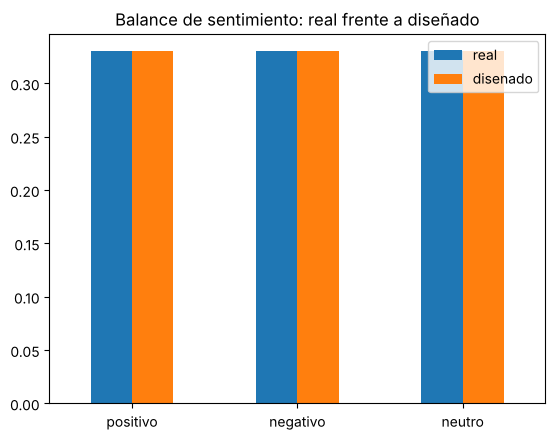

In [19]:
balance.plot.bar(rot=0, title="Balance de sentimiento: real frente a diseñado");

### 7.3 Lemas más frecuentes (sin palabras vacías)

In [20]:
lemas = [t.lemma_.lower() for d in docs for t in d if t.is_alpha and not t.is_stop and t.lemma_.lower() not in ETIQUETAS]
pd.DataFrame(Counter(lemas).most_common(15), columns=["lema", "frecuencia"])

,lema,frecuencia
0,pedir,4
1,servicio,4
2,volver,3
3,lugar,3
4,atención,3
5,comida,3
6,ajiaco,2
7,bandeja,2
8,precio,2
9,alto,2


### 7.4 Categorías gramaticales

NOUN     74
DET      51
ADJ      44
VERB     41
ADP      30
CCONJ    28
AUX      20
PROPN    20
Name: count, dtype: int64


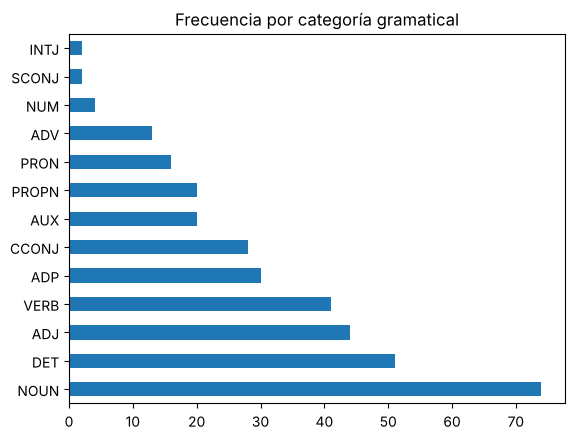

In [21]:
conteo_pos = pd.Series([t.pos_ for d in docs for t in d if not t.is_punct]).value_counts()
conteo_pos.plot.barh(title="Frecuencia por categoría gramatical")
print(conteo_pos.head(8))

### 7.5 Concordancias
Una concordancia muestra cada aparición de una palabra en su contexto (formato KWIC).

In [22]:
from nltk.text import Text
texto_nltk = Text([t.text for d in docs for t in d])
texto_nltk.concordance("servicio", width=70)

Displaying 4 of 4 matches:
ja paisa y llegó fría . Pésimo servicio . Buen ambiente en Chapinero ,
 domingo están buenísimos y el servicio fue muy amable . Mi comadre [ 
 por una sopa fría ! Excelente servicio , sí señor . El baño estaba su
la comida estaba insípida y el servicio es lentísimo . Pedí el menú ej


**EJERCICIO 7.1** Busquen las concordancias de otra palabra frecuente en su corpus. ¿Qué adjetivos la acompañan en las reseñas positivas y en las negativas?

In [23]:
# EJERCICIO: cambien la palabra
texto_nltk.concordance("bueno", width=70)

Displaying 1 of 1 matches:
info en El lugar es normal , ni bueno ni malo . Llamen al [ TELEFONO 


## 8. Documentar: ficha técnica del corpus
Un corpus solo es reutilizable si se documenta cómo se construyó (ver Gebru et al., *Datasheets for Datasets*, Communications of the ACM, 2021). Completen la ficha y guárdenla junto al corpus.

In [24]:
# EJERCICIO (resuelto): ficha técnica versión 0.2
ficha = {
    "nombre": "Mini corpus de reseñas de restaurantes de Bogotá",
    "version": VERSION,
    "fecha_creacion": str(date.today()),
    "cambios_respecto_a_v0_1": [
        "Se amplió el corpus de 9 a 30 reseñas (21 nuevas, escritas por estudiantes para la clase).",
        "Balance 10 positivas / 10 negativas / 10 neutras, igual al diseño (1/3 cada una).",
        "Se agregaron casos difíciles: ironía, reseñas mixtas, calificación que no coincide con el texto, emojis y datos personales.",
        "Segunda ronda de anotación con guía v2 (reglas para ironía, concesiones con 'pero' y calificación numérica).",
        "Se calculó el kappa de Cohen de la ronda 1 y se acordó una etiqueta final por consenso.",
        "Se completaron licencia, restricciones de uso y criterios de selección.",
    ],
    "proposito": OBJETIVO,
    "tareas_previstas": TAREAS_PREVISTAS,
    "poblacion": DISENO["poblacion"],
    "periodo": DISENO["periodo"],
    "fuentes": sorted(df["fuente"].unique().tolist()),
    "criterios_seleccion": "Reseñas en español sobre restaurantes de Bogotá, escritas entre 2023 y 2025, de entre 5 y 25 palabras, con una opinión sobre comida, servicio, precio o ambiente. Textos sintéticos o de clase; ninguna reseña copiada de plataformas comerciales.",
    "tamano": {"textos": len(docs), "tokens": n_tokens, "tipos": n_tipos},
    "balance_final": df["sentimiento"].value_counts().to_dict(),
    "anotacion": {
        "automatica": "spaCy es_core_news_sm: tokens, lemas, POS, entidades",
        "manual": "sentimiento pos/neg/neu, dos anotadores, guía v2, desacuerdos resueltos por consenso",
        "kappa_cohen_ronda1": round(k, 2),
        "acuerdo_observado_ronda1": round(sum(x == y for x, y in zip(anotador_A, anotador_B)) / len(df), 2),
        "coincidencia_con_calificacion": round(float((df.sentimiento == df.sent_desde_cal).mean()), 2),
    },
    "anonimizacion": "correos, teléfonos y cédulas por regex; nombres de persona por revisión manual (spaCy solo propone candidatos: marcó 11 candidatos, solo 3 eran nombres reales, y no detectó a Laura)",
    "licencia": "CC BY 4.0 (textos escritos por los autores del taller para uso académico)",
    "restricciones_uso": "Uso académico y de investigación. No usar para identificar personas ni negocios reales. Corpus muy pequeño: no sirve para entrenar modelos de producción.",
    "responsables": "[Completar: nombres de la pareja de anotadores]",
    "contacto": "[Completar: correo institucional]",
}
with open("ficha_tecnica.json", "w", encoding="utf-8") as f:
    json.dump(ficha, f, ensure_ascii=False, indent=2)
print(json.dumps(ficha, ensure_ascii=False, indent=2))

{
  "nombre": "Mini corpus de reseñas de restaurantes de Bogotá",
  "version": "0.2",
  "fecha_creacion": "2026-11-09",
  "cambios_respecto_a_v0_1": [
    "Se amplió el corpus de 9 a 30 reseñas (21 nuevas, escritas por estudiantes para la clase).",
    "Balance 10 positivas / 10 negativas / 10 neutras, igual al diseño (1/3 cada una).",
    "Se agregaron casos difíciles: ironía, reseñas mixtas, calificación que no coincide con el texto, emojis y datos personales.",
    "Segunda ronda de anotación con guía v2 (reglas para ironía, concesiones con 'pero' y calificación numérica).",
    "Se calculó el kappa de Cohen de la ronda 1 y se acordó una etiqueta final por consenso.",
    "Se completaron licencia, restricciones de uso y criterios de selección."
  ],
  "proposito": "Reunir reseñas en español de restaurantes de Bogotá para entrenar y evaluar un clasificador de sentimiento.",
  "tareas_previstas": [
    "clasificación de sentimiento",
    "estudio del vocabulario gastronómico"
  ],
  "

## 9. Descargar los archivos

In [25]:
try:
    from google.colab import files
    files.download("corpus_resenas.jsonl")
    files.download("ficha_tecnica.json")
except ImportError:
    print("Fuera de Colab: los archivos corpus_resenas.jsonl y ficha_tecnica.json quedaron en la carpeta actual.")

Fuera de Colab: los archivos corpus_resenas.jsonl y ficha_tecnica.json quedaron en la carpeta actual.


## Reto final
1. Lleven el corpus a **30 reseñas** respetando el balance del diseño.
2. Anoten el sentimiento con dos personas y logren un **kappa de 0,60 o más**, ajustando la guía si hace falta.
3. Comparen el sentimiento anotado con la `calificacion` (1 a 5). ¿Coinciden siempre? ¿Qué casos no?
4. Actualicen la ficha técnica a la versión 0.2 y describan qué cambió.
5. Redacten un **informe breve** (máximo una página) con sus conclusiones sobre el proceso de construcción del corpus. Usen la plantilla de la celda siguiente como guía.

**Preguntas de cierre**
- ¿Qué variedades del español quedan fuera de este corpus?
- ¿Qué errores cometería un modelo entrenado solo con estas reseñas?

## Informe final y conclusiones
*Nota: las anotaciones de los anotadores A y B de este cuaderno son un ejemplo de trabajo. Si la pareja anota por su cuenta, vuelvan a ejecutar el cuaderno y actualicen las cifras de este informe.*

### 1. Resumen del corpus construido
Se reunieron **30 reseñas** (9 iniciales y 21 escritas por estudiantes), de 11 localidades de Bogotá. El balance quedó exactamente como el diseño: **10 positivas, 10 negativas y 10 neutras** (33 % cada una). Las fechas van de marzo de 2023 a diciembre de 2025, dentro del periodo previsto. El corpus tiene **335 tokens y 195 tipos** (relación tipo/token de 0,58, alta porque el corpus es muy pequeño y los textos son cortos). Todas las reseñas son de clase, no extraídas de plataformas comerciales.

### 2. Calidad de la anotación
En la ronda 1 el acuerdo fue de **80 % (24 de 30)** y el **kappa de Cohen, 0,70** (nivel bueno), por encima de la meta de 0,60. Los 6 desacuerdos fueron reseñas mixtas con "pero" (índices 2, 8, 21, 25, 28) y una ironía (16): en las mixtas A tendía a `neu` y B a polarizar. Se resolvieron por consenso (solo la 21 cambió a `neg`) y la guía v2 agregó reglas para ironía, concesiones y calificación numérica.

### 3. Sentimiento frente a calificación numérica
Coincidieron **26 de 30 (87 %)** si se convierte 1-2 en neg, 3 en neu y 4-5 en pos. Las calificaciones 1 y 5 coincidieron siempre (13 de 13); los desajustes están en las intermedias. La 12 tiene 2 estrellas pero un texto positivo (la propia reseña dice que fue un error); la 16 tiene 4 estrellas pero es **ironía** negativa; la 23 ("nada especial") tiene 4 estrellas y es neutra; y la 28 es una opinión **mixta** con 2 estrellas.

### 4. Hallazgos lingüísticos
Lemas más frecuentes (sin palabras vacías): *pedir* y *servicio* (4), *volver*, *lugar*, *atención* y *comida* (3). Por categoría dominan NOUN (74), DET (51), ADJ (44) y VERB (41), como cabe esperar en textos de opinión. Errores de spaCy: marcó como persona (`PER`) "llegó fría" y "Pésimo"; propuso 11 candidatos a nombre, de los cuales solo 3 eran reales, y etiquetó a "Laura" como lugar; lematizó *paisa* como *país* y tomó *fría* por sustantivo. Por eso la anonimización se hizo con revisión manual.

### 5. Limitaciones del corpus
Quedan fuera el español costeño, paisa, rural y de otros países, el registro oral y los textos con faltas de ortografía; la jerga aparece apenas en "parce" o "chévere". Solo se cubre comida típica y de barrio, sin alta cocina ni cadenas. Un modelo entrenado solo aquí fallaría con la **ironía** (leería "¡Qué maravilla esperar una hora!" como positiva), con los "pero" y con vocabulario nuevo (platos o barrios ausentes), y aprendería palabras de este corpus como señales de sentimiento. Además, con 30 textos y un balance artificial de 1/3 no es representativo: en la realidad predominan las reseñas positivas.

### 6. Conclusión general
Construir un corpus es un proceso de decisiones documentadas: el diseño, la anonimización, la guía de anotación y la ficha técnica pesan tanto como los textos. Las herramientas automáticas (NER, lematizador) ayudan, pero se revisan a mano, y los casos difíciles (ironía, mezcla de opiniones, estrellas que no coinciden con el texto) son donde se mide la calidad real del corpus.